In [1]:
import os
import re
import pickle
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import glob
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

# Dataset Choice

In [2]:
json_dir = '../results/2024/'
save_db = 'windows_2024.pkl'

# Retrieve Results

In [3]:
flattened_data = []
json_files = glob.glob(os.path.join(json_dir, '*.json'))
for json_file in json_files: 
    with open(json_file, 'r') as f:
        try:
            data = json.load(f)
            for author_data in data:
                author = author_data['author']
                for window in author_data['windows']:
                    record = {
                        'author': author,
                        'start_index': window['start_index'],
                        'start_time': window['start_time'],
                        'end_index': window['end_index'],
                        'end_time': window['end_time'],
                        'timezones': window['timezones']
                    }
                    flattened_data.append(record)
        except Exception as e:
            print(f"Error processing file {json_file}: {e}")

df = pd.DataFrame(flattened_data)

Error processing file ../results/2024/af1aa96f31a617f882a08a20d921fd165a7c0c3957cdbc566ea1541cefde0545.json: Expecting ',' delimiter: line 1 column 2147479553 (char 2147479552)


In [4]:
starts = pd.to_datetime(df['start_time'])
ends = pd.to_datetime(df['end_time'])
df['duration'] = (ends - starts).dt.total_seconds() / 3600

Retrieving time: **7min**

## Saving and Loading Results

In [5]:
with open(save_db, 'wb') as f:
    pickle.dump(df, f)

Saving time: **3min**

In [6]:
with open(save_db, 'rb') as f:
    df = pickle.load(f)

Loading time: **2min**

In [7]:
df.head()

,author,start_index,start_time,end_index,end_time,timezones,duration
0,ce78d68d19d779994948d1eee959ab5d14c673b19ba33874be194c4996151139,325,2008-06-25T16:35:19Z,331,2008-06-26T14:29:32Z,"[0, -240, 0]",21.903611
1,ce78d68d19d779994948d1eee959ab5d14c673b19ba33874be194c4996151139,485,2008-08-19T17:03:06Z,509,2008-08-19T20:59:23Z,"[0, -240, 0, -240]",3.938056
2,ce78d68d19d779994948d1eee959ab5d14c673b19ba33874be194c4996151139,507,2008-08-19T20:18:05Z,515,2008-08-20T19:47:44Z,"[0, -240, 0, -240, 0]",23.494167
3,ce78d68d19d779994948d1eee959ab5d14c673b19ba33874be194c4996151139,527,2008-08-27T23:25:42Z,538,2008-08-28T20:12:12Z,"[-240, 0, -240, 0]",20.775000
4,ce78d68d19d779994948d1eee959ab5d14c673b19ba33874be194c4996151139,533,2008-08-28T19:00:36Z,546,2008-08-29T17:50:12Z,"[0, -240, 0]",22.826667


# Analysis

### Basic Stats

In [8]:
author_stats = pd.DataFrame({
    'total_windows': df.groupby('author').size(),
    'unique_patterns': df.groupby('author')['timezones'].apply(lambda x: len(set(tuple(tz) for tz in x))),
    'avg_changes_per_window': df.groupby('author')['timezones'].apply(lambda x: np.mean([len(tz) for tz in x])),
    'avg_window_durations': df.groupby('author')['duration'].mean()
})

**2min**

In [9]:
author_stats.head(2)

,total_windows,unique_patterns,avg_changes_per_window,avg_window_durations
author,,,,
000004ce1e8b2d27a17eff682ee038222519d0139e2e870128c713ef46ab1f20,1,1,4.0,13.420556
000014b10fb13559dfd44bc447b49334ffbbf793f8859e478bd369d384cdc013,8,4,3.5,12.445556


In [10]:
max_stats = {
    'total_windows': author_stats['total_windows'].idxmax(),
    'unique_patterns': author_stats['unique_patterns'].idxmax(),
    'avg_changes_per_window': author_stats['avg_changes_per_window'].idxmax(),
    'avg_window_durations': author_stats['avg_window_durations'].idxmin()
}

max_authors = pd.DataFrame({
    'statistic': max_stats.keys(),
    'author': max_stats.values(),
    'value': [author_stats.loc[max_stats[stat], stat] for stat in max_stats.keys()]
})
# what date for unique pattern ? Old ?
max_authors

,statistic,author,value
0,total_windows,d2833f622cce50d1194cabd68ab1f50be3f55e0d07acf37e525daae9ee13fa39,654208.00000
1,unique_patterns,d2833f622cce50d1194cabd68ab1f50be3f55e0d07acf37e525daae9ee13fa39,654159.00000
2,avg_changes_per_window,d7dfa50f20e7ffe1e3c76ef59c307de208bd5359ad161e691d6a2a9b724ebbac,5700.44186
3,avg_window_durations,0001a58dc89c12e4ba2fdf35a0e0b68f875aca61f71178adce47c2020505d0f8,0.00000


- a26a80aeb4898a459a3a870a9ebbc990fab48497417ff160ee90e5528b202744 -> Jeff Epler jepler@gmail.com
- a2043a2e733a2cf67eccfa901584bd9ad4b60a79816a76a87604125bffd8f6d1 -> shaun shaundindial030@gmail.com
- a1f7e48ff270892792bbbea3eba2553b98cdba80d1c89252c144e8360a352ebb -> rOpenSci Bot myrmecocystus+ropenscibot@gmail.com

### Effective window

In [13]:
avg_duration = author_stats['avg_window_durations']
smallest_durations = avg_duration.sort_values().head(10)
print("Top 10 authors with shortest average window duration")
print(smallest_durations)
# 0.0 is probably only bots
filtered_durations = avg_duration[(avg_duration >= 1) & (avg_duration < 2)]
print("Authors with average window duration between 1-2 hours:")
print(filtered_durations.head(10))

Top 10 authors with shortest average window duration
author
7182a4dd77d5826c85df9d461b6cb2d350b3ae7aadae035b42a2b935d3c6c276    0.0
9aab543bd71e2dce043d4f87e83f718ad656f5131977d943d064fe3a9f1b2067    0.0
63d3fdfedad12b848bb9dfaa7b92863e74b5b9948c54bc29d7112a86bb4537ed    0.0
16f596c65316e2a00d5ef3088ca824ce8740ad642784282605a462d283427f14    0.0
16f54d71b09477c8bbec329382b2b34bae323833814371c73879ffecb6bf6a23    0.0
76953e511a84370e4f46c40167c4219eaf885b33501d7b7a4332df464ea035ae    0.0
16f47a91219c5630d8c42533832fff8f3b990915aad0e1a2c61d8d42042a58fc    0.0
3071f5ae32109640256d45825494354259d62c7ebebc1bd6c44655fa81bedbb6    0.0
a7bc5822ceaace6c2842f131829f209cc7fdd7265e316aaf8c9c9e8a2a253032    0.0
f4a5244fc16de83943836b2437670cb452aefd37604d10b795cd006256118742    0.0
Name: avg_window_durations, dtype: float64
Authors with average window duration between 1-2 hours:
author
0002b5c7d16d92cb43bc61b16aed68e10d7f633bddb29543d44e7acd96af2ca4    1.391389
00032c2b7ee8862c4b40cf64029772b08d0b7

- a09227853d1dc6b05f5766c8ed052c0a0ef028dcba05339a4151e405affc446b 1.785556h -> jvivas jovies288@gmail.com
    - [{'start_index': 1, 'start_time': 1384313409, 'end_index': 9, 'end_time': 1384319837, 'timezones': [-360, -480, -360]}]

### Timezone Pattern

In [14]:
timezone_patterns = df.groupby('author')['timezones'].apply(
    lambda x: [tuple(w) for w in x]
)
common_patterns = pd.Series([p for patterns in timezone_patterns for p in patterns]).value_counts()

**2min**

In [15]:
long_patterns = [(pattern, common_patterns[pattern]) for pattern in common_patterns.keys() if len(set(pattern)) > 2]
sorted_long_patterns = sorted(long_patterns, key=lambda x: x[1], reverse=True)
print("Top 10 most frequent patterns with more than 2 unique timezones:")
for pattern, count in sorted_long_patterns[:10]:
    print(f"Pattern: {pattern}, Count: {count}")

Top 10 most frequent patterns with more than 2 unique timezones:
Pattern: (-420, 180, 120), Count: 1308
Pattern: (-420, 120, 180), Count: 1219
Pattern: (60, 0, 120), Count: 1156
Pattern: (120, 0, 60), Count: 1068
Pattern: (-240, 0, -420), Count: 1067
Pattern: (120, 60, 0), Count: 1002
Pattern: (120, 0, -420), Count: 978
Pattern: (-420, 0, 120), Count: 952
Pattern: (-420, -240, 0), Count: 920
Pattern: (60, 120, 0), Count: 907


**4minmin**

### Graphic

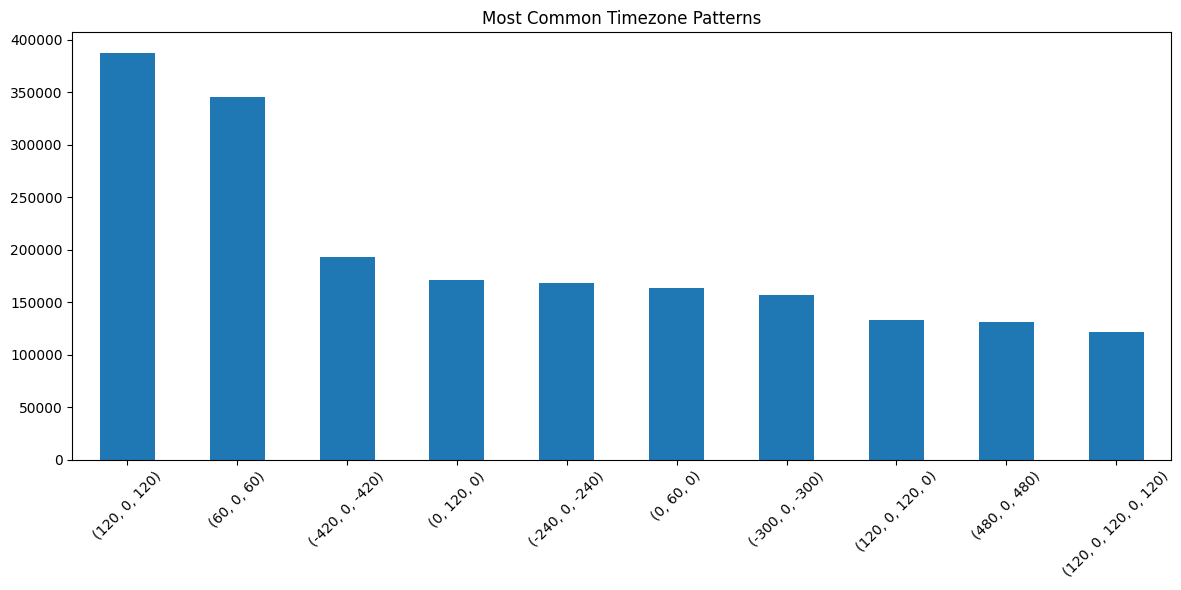

In [16]:
""" plt.figure(figsize=(10,6))
sns.histplot(data=[d for durations in window_durations for d in durations if isinstance(durations, list)])
plt.title('Window Durations Distribution')
plt.xlabel('Hours') """

plt.figure(figsize=(12,6))
common_patterns.head(10).plot(kind='bar')
plt.title('Most Common Timezone Patterns')
plt.xticks(rotation=45)
plt.tight_layout()